# 04 · One-stage anchor-based detector: RetinaNet

Covers the *One-stage Anchor-based* checkpoint.

**Same protocol as notebooks 02 and 03:** the identical exported training set, the same evaluator on all 2 846
val frames, input 1280×720, 8 epochs, batch 4, SGD with warm-up and step decay, mixed precision, horizontal flip,
seed 42, COCO-pretrained weights. lr 0.0025 = torchvision's RetinaNet recipe scaled to batch 4.

**Model:** torchvision RetinaNet, ResNet-50 + FPN (levels P3–P7), 9 anchors per location, focal loss for classification, L1 for box regression. Only the last classification layer is new.

**Experiments**

| id | what changes | type | motivation |
|---|---|---|---|
| N0 | torchvision defaults: anchors 32–512 px, IoU 0.5 / 0.4, focal α 0.25, γ 2, L1 box loss | training | baseline |
| N1 | anchors 8–128 px (same 3 scales × 3 ratios) | training | 01 §4.3: default anchors match 0% of objects < 16 px and 59% of 16–32 px; 8–128 px covers 99.9% |
| N2 | N1 + GIoU box loss | training, **loss** | same loss change as Faster R-CNN F2, so the two families can be compared |

**Runtime:** GPU, same account as notebook 03 is ideal . `SMOKE = True` first, then `SMOKE = False`. Every run checkpoints after each
epoch; after a disconnect just run everything again.

## 1. Setup

In [ ]:
# --- Download the competition data -----------------------------------------------------
# The Kaggle token is read from Colab Secrets (key icon -> KAGGLE_API_TOKEN, notebook access on);
# it is never written into the notebook.
import os, subprocess
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
print("Downloading competition dataset...")
subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", "/content", "-q"], check=True)
print("Extracting data...")
os.makedirs("/content/data", exist_ok=True)
subprocess.run(["unzip", "-q", "-o", f"/content/{COMPETITION}.zip", "-d", "/content/data"], check=True)
os.remove(f"/content/{COMPETITION}.zip")
print("Done! The /content/data/train folder has been created.")

Extracting data...
Done! The /content/data/train folder has been created.


In [ ]:
# --- Environment detection and paths (same as notebooks 01-03) -------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"   # Colab only: used to download the data

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:  # anywhere on Google Drive (unzipping often adds an extra visdrone-det/ level)
        for depth in range(0, 4):
            hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + "vdet/__init__.py"))
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet/ not found on Google Drive: upload the visdrone-det folder to MyDrive")
    if IN_KAGGLE:
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # results survive disconnects
    if not os.path.exists("/content/data/train"):
        # Kaggle API token, never written into the notebook (it goes to GitHub):
        # Colab sidebar -> key icon (Secrets) -> name KAGGLE_API_TOKEN, value KGAT_..., notebook access ON.
        # Fallback: a legacy kaggle.json in the MyDrive root.
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !pip -q install -U kaggle
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

for pkg, mod in [("pycocotools", "pycocotools")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

Mounted at /content/drive
repo: /content/drive/MyDrive/visdrone-det


In [ ]:
# --- Imports and configuration -------------------------------------------------------
import json, random, time
from dataclasses import asdict, replace
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torchvision

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, viz as V, yolo_export as YX, ultra as U
from vdet import tv_detect as TV, analysis as AN
from vdet.paths import find_data_root, default_work_dir

SMOKE = False               # True: tiny run to test the pipeline. False: the real experiments.
RUN = ["N0", "N1", "N2"]   # training runs for this session (finished ones are skipped)

SEED = 42
EPOCHS = 1 if SMOKE else 8 # same as Faster R-CNN
BATCH = 4
TRAIN_STEP, VAL_MONITOR_STEP, EXPORT_SIDE = 5, 3, 1280   # identical to notebooks 02, 03
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORKERS = min(4, os.cpu_count() or 2)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
TAG = "_smoke" if SMOKE else ""
RUNS_DIR = WORK_DIR / f"runs_retina{TAG}"
YOLO_DS = (Path("/tmp") if IN_KAGGLE else Path("/content") if IN_COLAB else WORK_DIR) / f"yolo_ds{TAG}"   # shared with 02/03
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
log = U.ResultsLog(WORK_DIR / f"results_retina{TAG}.json")

TRAIN_CFG = TV.TrainConfig(epochs=EPOCHS, batch=BATCH, lr=0.0025, milestones=(max(1, EPOCHS - 2),), workers=WORKERS,
                           seed=SEED, max_iters_per_epoch=20 if SMOKE else None)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "| workers", WORKERS)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device Tesla T4 | workers 2


## 2. Data: 

In [ ]:
tv = D.load_train_val(DATA_ROOT)
im = tv.images
train_keys = D.subsample_frames(im[im.split == "train"], TRAIN_STEP).key
monitor_keys = D.subsample_frames(im[im.split == "val"], VAL_MONITOR_STEP).key
eval_keys = im[im.split == "val"].key
if SMOKE:
    train_keys = D.subsample_frames(im[im.split == "train"], 200).key
    monitor_keys = eval_keys = D.subsample_frames(im[im.split == "val"], 100).key
train, monitor, val = tv.subset(train_keys), tv.subset(monitor_keys), tv.subset(eval_keys)
if not (YOLO_DS / "data.yaml").exists():      # already there if notebook 02/03 ran in this session
    display(YX.export_yolo_dataset(train, monitor, YOLO_DS, mask_train=True, mask_val=False, max_side=EXPORT_SIDE))
train_ds = TV.ExportedDetDataset(YOLO_DS, "train")
print("training frames:", len(train_ds), "| monitor frames:", len(monitor.images), "| eval frames:", len(val.images))

export train:   0%|          | 0/4868 [00:00<?, ?it/s]

export val:   0%|          | 0/951 [00:00<?, ?it/s]

,images,masked_images,boxes,dropped_boxes
train,4868,3644,220357,2522
val,951,0,38206,0


training frames: 4868 | monitor frames: 951 | eval frames: 2846


## 3. Experiments

In [ ]:
EXPERIMENTS = {
    "N0": {},
    "N1": dict(anchor_sizes=(8, 16, 32, 64, 128)),
    "N2": dict(anchor_sizes=(8, 16, 32, 64, 128), box_loss="giou"),
}
INFERENCE = {
    "default (300 det, score 0.05)": dict(detections_per_img=300, score_thresh=0.05, topk_candidates=1000),
    "500 det, score 0.001":          dict(detections_per_img=500, score_thresh=0.001, topk_candidates=1000),
}
MONITOR_INF = INFERENCE["500 det, score 0.001"]
cfgs = {k: replace(TV.RetinaConfig(), **v) for k, v in EXPERIMENTS.items()}
pd.DataFrame({k: asdict(c) for k, c in cfgs.items()}).T[["anchor_sizes", "fg_iou_thresh", "bg_iou_thresh",
    "focal_alpha", "focal_gamma", "box_loss"]]

,anchor_sizes,fg_iou_thresh,bg_iou_thresh,focal_alpha,focal_gamma,box_loss
N0,"(32, 64, 128, 256, 512)",0.5,0.4,0.25,2.0,l1
N1,"(8, 16, 32, 64, 128)",0.5,0.4,0.25,2.0,l1
N2,"(8, 16, 32, 64, 128)",0.5,0.4,0.25,2.0,giou


In [ ]:
ev_monitor = E.DetectionEvaluator(monitor)
ev = E.DetectionEvaluator(val)

def monitor_fn(model):
    """mAP on the monitor subset after an epoch (reads the downscaled export: fast)."""
    TV.set_inference_params(model, **MONITOR_INF)
    preds, _ = TV.predict_table(model, monitor.images, DEVICE, export_img_dir=YOLO_DS / "images/val",
                                batch=BATCH, workers=WORKERS, desc="monitor")
    m = ev_monitor.evaluate(preds, per_class=False)
    return {k: m[k] for k in ("mAP", "AP50", "AP_small")}

def run_experiment(name):
    cfg, run_dir = cfgs[name], RUNS_DIR / name
    model = TV.build_retinanet(cfg).to(DEVICE)
    if TV.is_finished(run_dir, EPOCHS):
        model.load_state_dict(torch.load(run_dir / "final.pth", map_location=DEVICE))
        print(f"{name}: already trained")
    else:
        print(f"{name}: training {EPOCHS} epochs (progress: {run_dir / 'history.csv'})")
        TV.train(model, train_ds, TRAIN_CFG, run_dir, DEVICE, monitor=monitor_fn, model_cfg=cfg)
    return model

def evaluate_variants(name, model, variants):
    for v in variants:
        TV.set_inference_params(model, **INFERENCE[v])
        preds, sec = TV.predict_table(model, val.images, DEVICE, batch=BATCH, workers=WORKERS, desc=f"val {name}")
        m = ev.evaluate(preds); m["ms_per_img"] = round(sec * 1000, 1)
        log.add(f"{name} | {v}", {**asdict(cfgs[name]), **INFERENCE[v]}, m)
        preds.to_csv(RUNS_DIR / name / f"val_preds_{list(INFERENCE).index(v)}.csv.gz", index=False)
        print(f"  {name} | {v}: mAP {m['mAP']*100:.1f}  AP50 {m['AP50']*100:.1f}  AP_small {m['AP_small']*100:.1f}  {m['ms_per_img']} ms/img")

In [ ]:
# --- Train and evaluate (the long cell) -------------------------------------------------
for name in RUN:
    model = run_experiment(name)
    variants = list(INFERENCE) if name == "N0" else list(INFERENCE)[1:]
    todo = [v for v in variants if f"{name} | {v}" not in log.data or SMOKE]
    if todo:
        evaluate_variants(name, model, todo)
    del model; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 165MB/s]


N0: already trained
N1: already trained
N2: already trained


val N2:   0%|          | 0/712 [00:00<?, ?it/s]

  N2 | 500 det, score 0.001: mAP 10.6  AP50 27.8  AP_small 4.5  128.7 ms/img


## 4. Results

In [ ]:
res = log.table()
cols = ["mAP", "AP50", "AP75", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR500"]
show = res[cols].astype(float).mul(100).round(1).join(res[["ms_per_img"]])
show.index.name = "run | test-time setting"
show

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,ms_per_img
run | test-time setting,,,,,,,,,
"N0 | default (300 det, score 0.05)",16.7,32.2,15.4,0.3,5.6,15.1,33.6,34.1,135.1
"N0 | 500 det, score 0.001",16.7,32.3,15.4,0.3,5.6,15.1,33.7,34.6,133.0
"N1 | 500 det, score 0.001",10.1,26.7,6.0,0.5,3.9,9.5,19.0,30.3,139.8
"N2 | 500 det, score 0.001",10.6,27.8,6.1,1.1,4.5,10.0,19.7,30.9,128.7


In [ ]:
pc = res[[f"AP_{c}" for c in CLASSES]].astype(float).mul(100).round(1)
pc.columns = CLASSES
pc

,person,bicycle,car,van,truck,tricycle,bus,motor
"N0 | default (300 det, score 0.05)",22.1,12.2,35.4,19.3,19.3,14.5,4.8,6.1
"N0 | 500 det, score 0.001",22.1,12.2,35.4,19.4,19.3,14.5,4.8,6.1
"N1 | 500 det, score 0.001",15.3,8.2,25.8,8.2,7.4,9.4,0.7,5.9
"N2 | 500 det, score 0.001",16.1,8.7,26.3,9.2,8.1,8.9,1.2,6.6


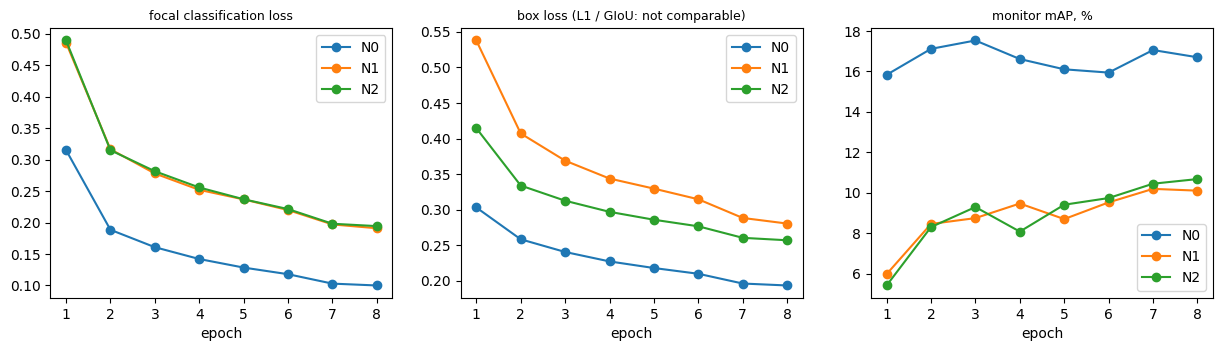

In [ ]:
hist = {n: pd.read_csv(RUNS_DIR / n / "history.csv") for n in EXPERIMENTS if (RUNS_DIR / n / "history.csv").exists()}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for n, h in hist.items():
    ax[0].plot(h.epoch, h.classification, "o-", label=n)
    ax[1].plot(h.epoch, h.bbox_regression, "o-", label=n)
    ax[2].plot(h.epoch, h.mAP * 100, "o-", label=n)
for a, t in zip(ax, ["focal classification loss", "box loss (L1 / GIoU: not comparable)", "monitor mAP, %"]):
    a.set_title(t, fontsize=9); a.set_xlabel("epoch"); a.legend()
fig.savefig(FIG_DIR / "retina_curves.png", bbox_inches="tight"); plt.show()

> **Observation.** N0 reaches 16.7 mAP. Unlike Faster R-CNN, 500 instead of 300 detections changes nothing.
> Smaller anchors collapse to 10.1 mAP, and AP75 falls from 15.4 to 6.0, so localisation gets much worse. Every
> class drops, large objects too: with base sizes up to 128 px the largest anchor is about 200 px,
> so big objects lose well-matching anchors. GIoU recovers only +0.5 mAP. Curves: N1 and N2 start far below N0
> and are still rising at epoch 8, while N0 is flat after epoch 2.

## 5. What changes without a proposal stage
A one-stage detector classifies **every anchor**; Faster R-CNN's RPN trains on 256 sampled anchors per image and
its RoI head on 512 sampled proposals with 25% positives. Below: anchors per image and how they are assigned under
RetinaNet's IoU thresholds, for the default and the small anchors, on 100 training frames. "Objects without a
positive anchor" receive no direct classification signal at all.

In [ ]:
stats = {}
for n in ("N0", "N1"):
    m = TV.build_retinanet(cfgs[n], pretrained=False)    # assignment depends only on anchors and thresholds
    stats[n] = TV.anchor_assignment_stats(m, train_ds, DEVICE, n_images=10 if SMOKE else 100).iloc[0]
    del m
pd.DataFrame(stats).T

,anchors,positive,ignored,negative,objects,objects_without_positive_%,small_objects_without_positive_%,negative : positive
N0,176580.0,639.4,1112.7,174828.0,43.8,1.2,2.1,273.4
N1,176580.0,95.8,135.1,176349.1,43.8,2.9,3.5,1841.2


> **Observation.** Without a proposal stage all 176 580 anchors of a frame are classified. With default anchors 639 per frame are
> positive; with 8–128 px anchors only 96, and 2.9% of objects get no
> positive anchor at all. On the stride-8 grid a small anchor rarely reaches IoU 0.5 with an object,
> because a shift of a few pixels changes IoU a lot. Smaller anchors therefore produced fewer positives, not more.
> The EDA coverage of 99.9% assumed anchors centred on each object and was misleading.

## 6. Comparison with the two-stage detector
Reads `results_frcnn.json` from this Drive (notebook 03). If Faster R-CNN was trained on another account,
copy that file into `WORK_DIR` first.

In [ ]:
frcnn_path = WORK_DIR / f"results_frcnn{TAG}.json"
rows = {f"RetinaNet {k}": v["metrics"] for k, v in log.data.items()}
if frcnn_path.exists():
    fr = json.loads(frcnn_path.read_text())
    best_f = max(fr, key=lambda k: fr[k]["metrics"]["mAP"])
    rows[f"Faster R-CNN {best_f}"] = fr[best_f]["metrics"]
    default_f = next((k for k in fr if k.startswith("F0 | default")), None)
    if default_f: rows[f"Faster R-CNN {default_f}"] = fr[default_f]["metrics"]
else:
    print("missing:", frcnn_path)
cmp = pd.DataFrame(rows).T
cmp[cols].astype(float).mul(100).round(1).join(cmp[["ms_per_img"]]).sort_values("mAP", ascending=False)

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,ms_per_img
"Faster R-CNN F0 | 500 det, score 0.001, 3000 prop.",19.8,41.8,16.5,1.9,9.7,18.0,36.1,38.4,150.8
"Faster R-CNN F0 | default (100 det, score 0.05, 1000 prop.)",17.8,36.0,15.6,1.7,9.1,15.9,32.8,25.9,134.4
"RetinaNet N0 | 500 det, score 0.001",16.7,32.3,15.4,0.3,5.6,15.1,33.7,34.6,133.0
"RetinaNet N0 | default (300 det, score 0.05)",16.7,32.2,15.4,0.3,5.6,15.1,33.6,34.1,135.1
"RetinaNet N2 | 500 det, score 0.001",10.6,27.8,6.1,1.1,4.5,10.0,19.7,30.9,128.7
"RetinaNet N1 | 500 det, score 0.001",10.1,26.7,6.0,0.5,3.9,9.5,19.0,30.3,139.8


In [ ]:
# Error types of the best RetinaNet run next to the best Faster R-CNN run (score >= 0.3)
BEST_KEY = max(log.data, key=lambda k: log.data[k]["metrics"]["mAP"])
BEST_RUN, BEST_INF = BEST_KEY.split(" | ")
print("best RetinaNet:", BEST_KEY)
types = {"RetinaNet " + BEST_RUN: AN.error_breakdown(
    pd.read_csv(RUNS_DIR / BEST_RUN / f"val_preds_{list(INFERENCE).index(BEST_INF)}.csv.gz"), val)}
fr_dir = WORK_DIR / f"runs_frcnn{TAG}"
if frcnn_path.exists():
    f_run = best_f.split(" | ")[0]
    f_files = sorted((fr_dir / f_run).glob("val_preds_*.csv.gz"))
    if f_files:
        types["Faster R-CNN " + f_run] = AN.error_breakdown(pd.read_csv(f_files[-1]), val)
display(pd.DataFrame({k: e["detections"]["share_%"] for k, e in types.items()}).fillna(0).T)
pd.DataFrame({k: e["misses"]["miss_rate_%"] for k, e in types.items()}).T.add_prefix("miss rate ")

best RetinaNet: N0 | 500 det, score 0.001


,background,class,duplicate,ignored,location,tp
RetinaNet N0,16.7,11.7,1.8,13.6,13.5,42.7
Faster R-CNN F0,12.8,9.9,1.0,15.3,12.6,48.4


,miss rate <16px,miss rate 16-32px,miss rate 32-96px,miss rate >96px
RetinaNet N0,88.0,66.8,44.6,14.3
Faster R-CNN F0,84.2,55.0,38.9,16.9


> **Observation.** Faster R-CNN F0 beats RetinaNet N0 by 3.1 mAP. The gap is mostly in small objects and AP50; large objects are close  and
> RetinaNet even misses slightly fewer objects above 96 px. RetinaNet has more background false positives and class errors. Speed is similar.

## 7. Test predictions and submission (best run and test-time setting)

In [ ]:
test = D.load_test_images(DATA_ROOT)
if SMOKE:
    test = test.groupby("clip").head(2)
model = TV.build_retinanet(cfgs[BEST_RUN]).to(DEVICE)
model.load_state_dict(torch.load(RUNS_DIR / BEST_RUN / "final.pth", map_location=DEVICE))
TV.set_inference_params(model, **INFERENCE[BEST_INF])
test_preds, sec = TV.predict_table(model, test, DEVICE, batch=BATCH, workers=WORKERS, desc="test")
test_preds.to_csv(WORK_DIR / f"test_preds_retina_{BEST_RUN}.csv.gz", index=False)
if not SMOKE:
    sub = S.write_submission(test_preds, DATA_ROOT, WORK_DIR / f"submission_retina_{BEST_RUN}.csv")
    display(sub.head(3))
print(f"{len(test_preds)} detections on {test.key.nunique()} test frames, {sec*1000:.0f} ms/img")

test:   0%|          | 0/953 [00:00<?, ?it/s]

saved /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/submission_retina_N0.csv: 3811 rows, 1711941 detections, 0 empty rows


,image_id,PredictionString
0,clip_001_0000001,0 0.9248 1655.3 792.3 61.5 142.0 0 0.9229 780....
1,clip_001_0000002,0 0.9429 775.3 893.5 64.9 172.1 0 0.9307 717.8...
2,clip_001_0000003,0 0.9399 1672.0 800.0 58.0 150.5 0 0.9341 710....


1898805 detections on 3811 test frames, 79 ms/img


## 8. Summary

Without a proposal stage RetinaNet classifies all ~177 000 anchors of a frame, of which only ~640 are positive.
Focal loss multiplies the loss of each anchor by (1 − p)^γ, so easy background anchors contribute almost nothing and
training focuses on the hard ones; the IoU thresholds 0.5 / 0.4 decide which anchors are positive, negative or
ignored. The anchors chosen from the data analysis hurt badly: small anchors gave 6.7× fewer
positives and the largest anchor became too small for big objects. GIoU gave +0.5 here and −0.3 in Faster R-CNN, a
small and inconsistent effect. The tuned Faster R-CNN is better at a similar
speed. **N0 goes forward:** public LB 0.2356.